In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import(
    accuracy_score,
    classification_report,
    confusion_matrix
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
df=pd.read_csv("../data/Dataset.csv")

In [3]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [4]:
df.shape


(8790, 10)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [6]:
df["type"].value_counts()

type
Movie      6126
TV Show    2664
Name: count, dtype: int64

In [7]:
df["type"].value_counts(normalize=True)*100

type
Movie      69.692833
TV Show    30.307167
Name: proportion, dtype: float64

In [8]:
df["rating"].value_counts()

rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64

In [9]:
df["duration"].value_counts().head(15)

duration
1 Season     1791
2 Seasons     421
3 Seasons     198
90 min        152
97 min        146
93 min        146
94 min        146
91 min        144
95 min        137
96 min        130
92 min        129
102 min       122
98 min        120
99 min        118
101 min       116
Name: count, dtype: int64

In [10]:
for col in df.columns:
    print(f"{col}:{df[col].nunique()} unique value")

show_id:8790 unique value
type:2 unique value
title:8787 unique value
director:4528 unique value
country:86 unique value
date_added:1713 unique value
release_year:74 unique value
rating:14 unique value
duration:220 unique value
listed_in:513 unique value


In [11]:
df["listed_in"].value_counts()

listed_in
Dramas, International Movies                                362
Documentaries                                               359
Stand-Up Comedy                                             334
Comedies, Dramas, International Movies                      274
Dramas, Independent Movies, International Movies            252
                                                           ... 
Anime Features                                                1
Action & Adventure, Horror Movies, Independent Movies         1
Action & Adventure, Classic Movies, International Movies      1
Cult Movies, Independent Movies, Thrillers                    1
Classic & Cult TV, Crime TV Shows, TV Dramas                  1
Name: count, Length: 513, dtype: int64

In [12]:
df["country"].value_counts()

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
                  ... 
Iran                 1
West Germany         1
Greece               1
Zimbabwe             1
Soviet Union         1
Name: count, Length: 86, dtype: int64

In [13]:
X=df[["country","release_year","rating","listed_in"]]

y=df["type"]

In [14]:
print("Feature shape",X.shape)
print("Target shape",y.shape)

Feature shape (8790, 4)
Target shape (8790,)


In [15]:
from sklearn.model_selection import train_test_split

X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,  #20% testing, 80% training
    random_state=42, #Makes the split reproducible
    stratify=y
)

In [16]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (7032, 4)
X_test: (1758, 4)

y_train: (7032,)
y_test: (1758,)


In [17]:
print("Original distribution")
print(y.value_counts(normalize=True)*100)

print("Training distribution")
print(y_train.value_counts(normalize=True)*100)

print("Testing distribution")
print(y_test.value_counts(normalize=True)*100)


Original distribution
type
Movie      69.692833
TV Show    30.307167
Name: proportion, dtype: float64
Training distribution
type
Movie      69.695677
TV Show    30.304323
Name: proportion, dtype: float64
Testing distribution
type
Movie      69.681456
TV Show    30.318544
Name: proportion, dtype: float64


In [18]:
X_train.dtypes

country         object
release_year     int64
rating          object
listed_in       object
dtype: object

In [19]:
X_train.head(10)

,country,release_year,rating,listed_in
5268,India,1972,TV-14,"International Movies, Romantic Movies"
123,Pakistan,2021,TV-MA,"International TV Shows, Romantic TV Shows, TV ..."
2901,Spain,2019,TV-MA,"Dramas, International Movies"
6170,United States,2009,R,"Comedies, Dramas"
5423,India,2006,TV-14,"Comedies, Dramas, International Movies"
8590,United States,2015,TV-MA,"TV Comedies, TV Dramas"
6133,United States,2013,R,"Dramas, Thrillers"
6481,Peru,2016,TV-14,"Documentaries, International Movies"
7843,United States,2018,TV-MA,"Documentaries, Music & Musicals"
7754,Japan,2019,TV-MA,"International TV Shows, Romantic TV Shows, TV ..."


In [20]:
from sklearn.preprocessing import OneHotEncoder,MultiLabelBinarizer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [21]:
genres=[]

for item in X_train["listed_in"]:
    genre_list=[]
    for genre in item.split(","):
        genre_list.append(genre.strip())
    genres.append(genre_list)
genres[:5]

[['International Movies', 'Romantic Movies'],
 ['International TV Shows', 'Romantic TV Shows', 'TV Comedies'],
 ['Dramas', 'International Movies'],
 ['Comedies', 'Dramas'],
 ['Comedies', 'Dramas', 'International Movies']]

In [22]:
from sklearn.preprocessing import MultiLabelBinarizer
mlb=MultiLabelBinarizer()

genre_encoded=mlb.fit_transform(genres)
print("Encoded shape",genre_encoded.shape)
print("Genre_name",mlb.classes_[:10])

Encoded shape (7032, 42)
Genre_name ['Action & Adventure' 'Anime Features' 'Anime Series' 'British TV Shows'
 'Children & Family Movies' 'Classic & Cult TV' 'Classic Movies'
 'Comedies' 'Crime TV Shows' 'Cult Movies']


In [23]:
genre_df = pd.DataFrame(
    genre_encoded,
    columns=mlb.classes_,
    index=X_train.index
)

genre_df.head()

,Action & Adventure,Anime Features,Anime Series,British TV Shows,Children & Family Movies,Classic & Cult TV,Classic Movies,Comedies,Crime TV Shows,Cult Movies,...,TV Action & Adventure,TV Comedies,TV Dramas,TV Horror,TV Mysteries,TV Sci-Fi & Fantasy,TV Shows,TV Thrillers,Teen TV Shows,Thrillers
5268,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
123,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,0,0,0,0,0
2901,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6170,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
5423,0,0,0,0,0,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [24]:
from sklearn.preprocessing import OneHotEncoder
encoder=OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

In [25]:
categorical_train=encoder.fit_transform(
    X_train[["country","rating"]]
)

In [26]:
print("Encoded shape",categorical_train.shape)
print("Features names")

print(encoder.get_feature_names_out())

Encoded shape (7032, 93)
Features names
['country_Argentina' 'country_Australia' 'country_Austria'
 'country_Bangladesh' 'country_Belgium' 'country_Brazil'
 'country_Bulgaria' 'country_Cambodia' 'country_Cameroon' 'country_Canada'
 'country_Chile' 'country_China' 'country_Colombia' 'country_Croatia'
 'country_Cyprus' 'country_Czech Republic' 'country_Denmark'
 'country_Egypt' 'country_Finland' 'country_France' 'country_Germany'
 'country_Ghana' 'country_Greece' 'country_Guatemala' 'country_Hong Kong'
 'country_Hungary' 'country_Iceland' 'country_India' 'country_Indonesia'
 'country_Ireland' 'country_Israel' 'country_Italy' 'country_Jamaica'
 'country_Japan' 'country_Jordan' 'country_Kenya' 'country_Kuwait'
 'country_Lebanon' 'country_Luxembourg' 'country_Malaysia'
 'country_Mauritius' 'country_Mexico' 'country_Mozambique'
 'country_Netherlands' 'country_New Zealand' 'country_Nigeria'
 'country_Norway' 'country_Not Given' 'country_Pakistan'
 'country_Paraguay' 'country_Peru' 'country_Ph

In [27]:
categorical_df=pd.DataFrame(
    categorical_train,
    columns=encoder.get_feature_names_out(),
    index=X_train.index 
)
categorical_df.head()

,country_Argentina,country_Australia,country_Austria,country_Bangladesh,country_Belgium,country_Brazil,country_Bulgaria,country_Cambodia,country_Cameroon,country_Canada,...,rating_PG-13,rating_R,rating_TV-14,rating_TV-G,rating_TV-MA,rating_TV-PG,rating_TV-Y,rating_TV-Y7,rating_TV-Y7-FV,rating_UR
5268,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
123,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2901,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
6170,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5423,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [28]:
year_df=X_train[["release_year"]].copy()
year_df.head(10)

,release_year
5268,1972
123,2021
2901,2019
6170,2009
5423,2006
8590,2015
6133,2013
6481,2016
7843,2018
7754,2019


In [29]:
X_train_processed = pd.concat(
    [year_df, categorical_df, genre_df],
    axis=1
)

X_train_processed.head()

,release_year,country_Argentina,country_Australia,country_Austria,country_Bangladesh,country_Belgium,country_Brazil,country_Bulgaria,country_Cambodia,country_Cameroon,...,TV Action & Adventure,TV Comedies,TV Dramas,TV Horror,TV Mysteries,TV Sci-Fi & Fantasy,TV Shows,TV Thrillers,Teen TV Shows,Thrillers
5268,1972,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
123,2021,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,1,0,0,0,0,0,0,0,0
2901,2019,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
6170,2009,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
5423,2006,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [30]:
print("Original training data:", X_train.shape)
print("Processed training data:", X_train_processed.shape)

Original training data: (7032, 4)
Processed training data: (7032, 136)


In [31]:
genres_test=[]
for item in X_test["listed_in"]:
    genre_list=[]
    for genre in item.split(","):
        genre_list.append(genre.strip())

    genres_test.append(genre_list)

genres_test[:5]

[['Documentaries', 'International Movies'],
 ['Children & Family Movies'],
 ['Dramas', 'Independent Movies', 'International Movies'],
 ['Movies'],
 ['TV Comedies', 'TV Dramas']]

In [32]:
genre_encoded_test=mlb.transform(genres_test)

In [33]:
print("Test genre shape",genre_encoded_test.shape)

Test genre shape (1758, 42)


In [34]:
from sklearn.preprocessing import OneHotEncoder

In [35]:
categorical_test=encoder.transform(
    X_test[["country","rating"]]
)
print("Encoded test shape",categorical_test.shape)

Encoded test shape (1758, 93)


In [36]:
year_train=X_train[["release_year"]].reset_index(drop=True)
year_test=X_test[["release_year"]].reset_index(drop=True)

print("Train year shape",year_train.shape)
print("Test year shape",year_test.shape)

Train year shape (7032, 1)
Test year shape (1758, 1)


In [37]:
# Convert encoded categorical arrays into DataFrames

categorical_columns = encoder.get_feature_names_out(
    ["country", "rating"]
)

categorical_train_df = pd.DataFrame(
    categorical_train,
    columns=categorical_columns
)

categorical_test_df = pd.DataFrame(
    categorical_test,
    columns=categorical_columns
)

# Combine categorical and numerical features

X_train_final = pd.concat(
    [categorical_train_df, year_train],
    axis=1
)

X_test_final = pd.concat(
    [categorical_test_df, year_test],
    axis=1
)

# Check final shapes

print("Final training shape:", X_train_final.shape)
print("Final testing shape:", X_test_final.shape)

Final training shape: (7032, 94)
Final testing shape: (1758, 94)


In [38]:
print("Are columns identical:",
      X_train_final.columns.equals(X_test_final.columns))

print("Missing values in training:",
      X_train_final.isnull().sum().sum())

print("Missing values in testing:",
      X_test_final.isnull().sum().sum())

Are columns identical: True
Missing values in training: 0
Missing values in testing: 0


In [39]:
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training target shape: (7032,)
Testing target shape: (1758,)

Training target distribution:
type
Movie      4901
TV Show    2131
Name: count, dtype: int64

Testing target distribution:
type
Movie      1225
TV Show     533
Name: count, dtype: int64


In [40]:
from sklearn.linear_model import LogisticRegression

In [41]:
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [42]:
lr_model.fit(X_train_final,y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lb

In [43]:
y_pred_lr=lr_model.predict(X_test_final)
print("First 10 actual value")

print(y_test.head(10).values)
print("\nFirst 10 predicted value")
print(y_pred_lr[:10])

First 10 actual value
['Movie' 'Movie' 'Movie' 'Movie' 'TV Show' 'Movie' 'TV Show' 'Movie'
 'Movie' 'Movie']

First 10 predicted value
['Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie'
 'Movie']


In [44]:
import pandas as pd
print("Actual distribution")
print(y_test.value_counts())

print("Predicted Distribution:")
print(pd.Series(y_pred_lr).value_counts())


Actual distribution
type
Movie      1225
TV Show     533
Name: count, dtype: int64
Predicted Distribution:
Movie      1444
TV Show     314
Name: count, dtype: int64


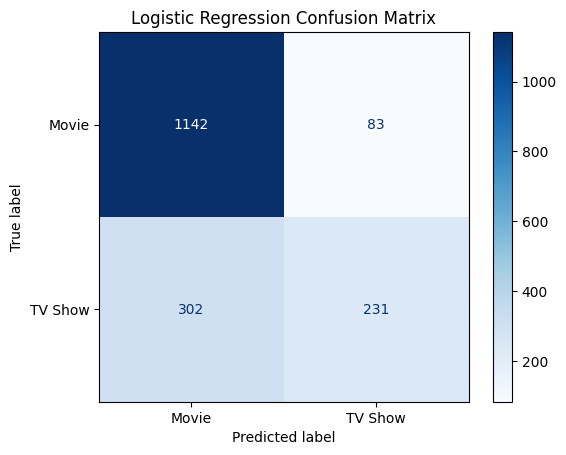

In [45]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
cm=confusion_matrix(y_test,y_pred_lr)
disp=ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Movie","TV Show"]
)
disp.plot(cmap="Blues")
plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [46]:
print(cm)

[[1142   83]
 [ 302  231]]


In [47]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred_lr))

              precision    recall  f1-score   support

       Movie       0.79      0.93      0.86      1225
     TV Show       0.74      0.43      0.55       533

    accuracy                           0.78      1758
   macro avg       0.76      0.68      0.70      1758
weighted avg       0.77      0.78      0.76      1758



In [48]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score,classification_report
dt_model=DecisionTreeClassifier(
    random_state=42
)
dt_model.fit(X_train_final,y_train)
y_pred_dt=dt_model.predict(X_test_final)
print("Decision Tree Accuracy:",accuracy_score(y_test,y_pred_dt))
print(classification_report(y_test,y_pred_dt))

Decision Tree Accuracy: 0.7775881683731513
              precision    recall  f1-score   support

       Movie       0.81      0.88      0.85      1225
     TV Show       0.66      0.54      0.60       533

    accuracy                           0.78      1758
   macro avg       0.74      0.71      0.72      1758
weighted avg       0.77      0.78      0.77      1758



In [49]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
rf_model=RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train_final,y_train)
y_pred_rf=rf_model.predict(X_test_final)
print("Random Forest Accuracy:",accuracy_score(y_test,y_pred_rf))
print(classification_report(y_test,y_pred_rf))

Random Forest Accuracy: 0.7832764505119454
              precision    recall  f1-score   support

       Movie       0.82      0.88      0.85      1225
     TV Show       0.67      0.57      0.62       533

    accuracy                           0.78      1758
   macro avg       0.75      0.72      0.73      1758
weighted avg       0.78      0.78      0.78      1758



In [50]:
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree", "Random Forest"],
    "Accuracy": [0.7804, 0.7776, 0.7833],
    "Macro F1": [0.70, 0.72, 0.73],
    "Weighted F1": [0.76, 0.77, 0.78]
})

print(results.sort_values(by="Macro F1", ascending=False))

                 Model  Accuracy  Macro F1  Weighted F1
2        Random Forest    0.7833      0.73         0.78
1        Decision Tree    0.7776      0.72         0.77
0  Logistic Regression    0.7804      0.70         0.76


In [51]:
print("Training target distribution:")
print(y_train.value_counts())

print("\nTraining target percentage:")
print(y_train.value_counts(normalize=True) * 100)

Training target distribution:
type
Movie      4901
TV Show    2131
Name: count, dtype: int64

Training target percentage:
type
Movie      69.695677
TV Show    30.304323
Name: proportion, dtype: float64


In [52]:
rf_balanced=RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)
rf_balanced.fit(X_train_final,y_train)
y_pred_balanced=rf_balanced.predict(X_test_final)
print("Balanced Random Forest Accuracy:",accuracy_score(y_test,y_pred_balanced))

print(classification_report(y_test,y_pred_balanced))

Balanced Random Forest Accuracy: 0.7474402730375427
              precision    recall  f1-score   support

       Movie       0.88      0.74      0.80      1225
     TV Show       0.56      0.77      0.65       533

    accuracy                           0.75      1758
   macro avg       0.72      0.75      0.73      1758
weighted avg       0.78      0.75      0.76      1758



In [53]:
from sklearn.metrics import confusion_matrix

print("Original Random Forest:")
print(confusion_matrix(y_test,y_pred_rf))

print("\nBalanced Random Forest")
print(confusion_matrix(y_test, y_pred_balanced))

Original Random Forest:
[[1072  153]
 [ 228  305]]

Balanced Random Forest
[[904 321]
 [123 410]]


In [54]:
rf_custom = RandomForestClassifier(
    n_estimators=100,
    class_weight={
        "Movie": 1,
        "TV Show": 1.5
    },
    random_state=42,
    n_jobs=-1
)

rf_custom.fit(X_train_final, y_train)

y_pred_custom = rf_custom.predict(X_test_final)

print("Custom Random Forest Accuracy:",
      accuracy_score(y_test, y_pred_custom))

print(classification_report(y_test, y_pred_custom))

Custom Random Forest Accuracy: 0.7736063708759955
              precision    recall  f1-score   support

       Movie       0.85      0.83      0.84      1225
     TV Show       0.62      0.65      0.64       533

    accuracy                           0.77      1758
   macro avg       0.73      0.74      0.74      1758
weighted avg       0.78      0.77      0.78      1758



In [55]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Original RF": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Balanced RF": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Custom RF": RandomForestClassifier(
        n_estimators=100,
        class_weight={"Movie": 1, "TV Show": 1.5},
        random_state=42,
        n_jobs=-1
    )
}

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train_final,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    print(f"\n{name}")
    print("CV Macro F1:", scores.mean().round(4))
    print("Standard Deviation:", scores.std().round(4))


Original RF
CV Macro F1: 0.728
Standard Deviation: 0.0201

Balanced RF
CV Macro F1: 0.7218
Standard Deviation: 0.0154

Custom RF
CV Macro F1: 0.7321
Standard Deviation: 0.0167


In [56]:
final_model = RandomForestClassifier(
    n_estimators=100,
    class_weight={
        "Movie": 1,
        "TV Show": 1.5
    },
    random_state=42,
    n_jobs=-1
)

# Train on the complete training dataset
final_model.fit(X_train_final, y_train)

# Predict on test dataset
y_pred_final = final_model.predict(X_test_final)

print("Final Model Accuracy:",
      accuracy_score(y_test, y_pred_final))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))

Final Model Accuracy: 0.7736063708759955

Classification Report:
              precision    recall  f1-score   support

       Movie       0.85      0.83      0.84      1225
     TV Show       0.62      0.65      0.64       533

    accuracy                           0.77      1758
   macro avg       0.73      0.74      0.74      1758
weighted avg       0.78      0.77      0.78      1758



In [57]:
import joblib

joblib.dump(final_model, "netflix_content_classifier.pkl")

print("Model saved successfully!")

Model saved successfully!


In [58]:
joblib.dump(
    X_train_final.columns.tolist(),
    "feature_columns.pkl"
)

['feature_columns.pkl']

In [ ]:
import joblib
import numpy as np

# Load saved model
loaded_model = joblib.load("netflix_content_classifier.pkl")

# Load feature columns
loaded_columns = joblib.load("feature_columns.pkl")

# Verify feature consistency
print("Saved features:", len(loaded_columns))
print("Training features:", X_train_final.shape[1])

# Make predictions using loaded model
test_predictions = loaded_model.predict(X_test_final)

# Compare predictions
print("Original predictions:", y_pred_final[:10])
print("Loaded model predictions:", test_predictions[:10])

print(
    "Predictions match:",
    np.array_equal(y_pred_final, test_predictions)
)

Saved features: 94
Training features: 94
Original predictions: ['Movie' 'Movie' 'TV Show' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie'
 'Movie']
Loaded model predictions: ['Movie' 'Movie' 'TV Show' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie' 'Movie'
 'Movie']
Predictions match: True


In [60]:
# Check whether the encoder still exists
print("Encoder:", encoder)

# Check encoder feature names
print("\nEncoded feature names:")
print(encoder.get_feature_names_out(["country", "rating"]))

# Check missing values in training data
print("\nMissing values:")
print(X_train[["country", "rating", "release_year"]].isnull().sum())

# Check training data
print("\nTraining data:")
print(X_train[["country", "rating", "release_year"]].head())

# Check final feature columns
print("\nFinal feature count:", len(X_train_final.columns))
print("Feature columns match:", 
      list(X_train_final.columns) == loaded_columns)

Encoder: OneHotEncoder(handle_unknown='ignore', sparse_output=False)

Encoded feature names:
['country_Argentina' 'country_Australia' 'country_Austria'
 'country_Bangladesh' 'country_Belgium' 'country_Brazil'
 'country_Bulgaria' 'country_Cambodia' 'country_Cameroon' 'country_Canada'
 'country_Chile' 'country_China' 'country_Colombia' 'country_Croatia'
 'country_Cyprus' 'country_Czech Republic' 'country_Denmark'
 'country_Egypt' 'country_Finland' 'country_France' 'country_Germany'
 'country_Ghana' 'country_Greece' 'country_Guatemala' 'country_Hong Kong'
 'country_Hungary' 'country_Iceland' 'country_India' 'country_Indonesia'
 'country_Ireland' 'country_Israel' 'country_Italy' 'country_Jamaica'
 'country_Japan' 'country_Jordan' 'country_Kenya' 'country_Kuwait'
 'country_Lebanon' 'country_Luxembourg' 'country_Malaysia'
 'country_Mauritius' 'country_Mexico' 'country_Mozambique'
 'country_Netherlands' 'country_New Zealand' 'country_Nigeria'
 'country_Norway' 'country_Not Given' 'country_Pak

In [61]:
# Encoder configuration
print("Encoder parameters:")
print(encoder.get_params())

# Categories learned during training
print("\nLearned categories:")
for column, categories in zip(
    ["country", "rating"],
    encoder.categories_
):
    print(f"\n{column}:")
    print(categories)

# Missing values in original training data
print("\nMissing values:")
print(X_train[["country", "rating", "release_year"]].isnull().sum())

# Original training columns
print("\nTraining columns:")
print(X_train[["country", "rating", "release_year"]].head())

Encoder parameters:
{'categories': 'auto', 'drop': None, 'dtype': <class 'numpy.float64'>, 'feature_name_combiner': 'concat', 'handle_unknown': 'ignore', 'max_categories': None, 'min_frequency': None, 'sparse_output': False}

Learned categories:

country:
['Argentina' 'Australia' 'Austria' 'Bangladesh' 'Belgium' 'Brazil'
 'Bulgaria' 'Cambodia' 'Cameroon' 'Canada' 'Chile' 'China' 'Colombia'
 'Croatia' 'Cyprus' 'Czech Republic' 'Denmark' 'Egypt' 'Finland' 'France'
 'Germany' 'Ghana' 'Greece' 'Guatemala' 'Hong Kong' 'Hungary' 'Iceland'
 'India' 'Indonesia' 'Ireland' 'Israel' 'Italy' 'Jamaica' 'Japan' 'Jordan'
 'Kenya' 'Kuwait' 'Lebanon' 'Luxembourg' 'Malaysia' 'Mauritius' 'Mexico'
 'Mozambique' 'Netherlands' 'New Zealand' 'Nigeria' 'Norway' 'Not Given'
 'Pakistan' 'Paraguay' 'Peru' 'Philippines' 'Poland' 'Portugal'
 'Puerto Rico' 'Romania' 'Russia' 'Saudi Arabia' 'Serbia' 'Singapore'
 'Slovenia' 'South Africa' 'South Korea' 'Soviet Union' 'Spain' 'Sweden'
 'Switzerland' 'Syria' 'Taiwan' '

In [62]:
import pandas as pd

# Check missing values in original training data
print("Missing values in X_train:")
print(X_train[["country", "rating", "release_year"]].isnull().sum())

# Check missing values in final training data
print("\nMissing values in X_train_final:")
print(X_train_final.isnull().sum().sum())

# Check data types
print("\nData types:")
print(X_train[["country", "rating", "release_year"]].dtypes)

# Check how final features were arranged
print("\nFirst 10 feature columns:")
print(X_train_final.columns[:10].tolist())

# Check year column
print("\nRelease year sample:")
print(X_train["release_year"].head())

Missing values in X_train:
country         0
rating          0
release_year    0
dtype: int64

Missing values in X_train_final:
0

Data types:
country         object
rating          object
release_year     int64
dtype: object

First 10 feature columns:
['country_Argentina', 'country_Australia', 'country_Austria', 'country_Bangladesh', 'country_Belgium', 'country_Brazil', 'country_Bulgaria', 'country_Cambodia', 'country_Cameroon', 'country_Canada']

Release year sample:
5268    1972
123     2021
2901    2019
6170    2009
5423    2006
Name: release_year, dtype: int64


In [63]:

import pandas as pd

def preprocess_new_data(data):

    # 1. Check required columns
    required_columns = ["country", "rating", "release_year"]

    for col in required_columns:
        if col not in data.columns:
            raise ValueError(f"Missing required column: {col}")

    # 2. Select columns in the correct order
    data = data[required_columns].copy()

    # 3. Check missing values
    if data.isnull().any().any():
        raise ValueError("Input data contains missing values.")

    # 4. Ensure release_year is numeric
    data["release_year"] = pd.to_numeric(
        data["release_year"],
        errors="raise"
    )

    # 5. Apply the already-fitted encoder
    encoded_data = encoder.transform(
        data[["country", "rating"]]
    )

    # 6. Get encoded feature names
    encoded_columns = encoder.get_feature_names_out(
        ["country", "rating"]
    )

    # 7. Convert encoded data into DataFrame
    encoded_df = pd.DataFrame(
        encoded_data,
        columns=encoded_columns,
        index=data.index
    )

    # 8. Add numerical release_year
    processed_data = pd.concat(
        [
            encoded_df,
            data[["release_year"]]
        ],
        axis=1
    )

    # 9. Maintain original 94 feature columns and order
    processed_data = processed_data.reindex(
        columns=loaded_columns,
        fill_value=0
    )

    return processed_data


In [64]:
new_netflix_data = pd.DataFrame({
    "country": ["India", "South Korea"],
    "rating": ["TV-14", "TV-MA"],
    "release_year": [2024, 2023]
})

# Apply preprocessing
processed_data = preprocess_new_data(new_netflix_data)

# Inspect results
print("Processed shape:", processed_data.shape)

print("\nFirst 5 columns:")
print(processed_data.iloc[:, :5])

print("\nFeature consistency:")
print(list(processed_data.columns) == loaded_columns)

Processed shape: (2, 94)

First 5 columns:
   country_Argentina  country_Australia  country_Austria  country_Bangladesh  \
0                0.0                0.0              0.0                 0.0   
1                0.0                0.0              0.0                 0.0   

   country_Belgium  
0              0.0  
1              0.0  

Feature consistency:
True


In [65]:
predictions = loaded_model.predict(processed_data)

for i, prediction in enumerate(predictions):
    print(
        f"Netflix Record {i+1}: "
        f"{prediction}"
    )

Netflix Record 1: Movie
Netflix Record 2: Movie
